# Offset between GALAH and LAMOST

In this jupyter we investigate the offset in different parameters between GALAH and LAMOST stars used in our sample 


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
from scipy import stats
import astropy

#Very important import
from breidablik.interpolate.nlte import Nlte

In [62]:
# Constants

LI_ABUNDANCE_SUN = 1.05 # Asplund et al. (2009)

## Offset in Abundances of lithium

### LAMOST vs GALAH DR3

First we will try our metogology for testing offsets

In [84]:
data_path = '../../data/LAMOST_catalog/'

GALAHDR3_x_LAMOST = pd.read_csv(data_path + 'LAMOST_x_GALAHDR3.csv')

#Li_fe
#e_Li_fe


In [85]:
GALAHDR3_x_LAMOST = GALAHDR3_x_LAMOST[
    (GALAHDR3_x_LAMOST['flag_fe_h'] == False) #sure. Good abundance flag
    &(GALAHDR3_x_LAMOST['flag_Li_fe'] == False) #sure.
    &(GALAHDR3_x_LAMOST['snr_c3_iraf'] > 30) #sure. Average SNR per pixel in the CCD3 (green) spectrum > 30
    &(GALAHDR3_x_LAMOST['flag_sp'] == 0) #sure
    &(GALAHDR3_x_LAMOST['S_N'] > 20)  #sure. Recomendation Ding et al 2024
    #&(GALAHDR3_x_LAMOST['Lim'] == 0)  # detections only
    &(GALAHDR3_x_LAMOST['e_DelA_Li_'] < 0.2) #not sure
    &(GALAHDR3_x_LAMOST['e_Li_fe'] < 0.2)
    &(GALAHDR3_x_LAMOST['e_fe_h']< 0.2)
].copy()
print(f'Matched stars: {len(GALAHDR3_x_LAMOST)}')


Matched stars: 2522


In [86]:
# Compares 1D-LTE Li abundances from GALAH and 1D-LTE LAMOST for the same stars
GALAHDR3_x_LAMOST['a_li_lamost'] = GALAHDR3_x_LAMOST['A_Li_']
GALAHDR3_x_LAMOST['a_li_galah'] = GALAHDR3_x_LAMOST['Li_fe'] + GALAHDR3_x_LAMOST['fe_h'] + LI_ABUNDANCE_SUN

GALAHDR3_x_LAMOST['delta_a_li'] = GALAHDR3_x_LAMOST['a_li_galah'] - GALAHDR3_x_LAMOST['a_li_lamost']


med_offset = GALAHDR3_x_LAMOST['delta_a_li'].median()
std_offset = GALAHDR3_x_LAMOST['delta_a_li'].std()
mad_offset = stats.median_abs_deviation(GALAHDR3_x_LAMOST['delta_a_li'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): -0.342 dex
Standard Deviation: 0.218 dex
Median Absolute Deviation: 0.108 dex


### 3D NLTE of GALAH vs 1D LTE from LAMOST

In [66]:
# For K2_TESS_GALAH
data_path = '../../data/extra_catalogs/'

K2_x_GALAH_catalog = pd.read_csv(data_path + 'K2_x_GALAH.csv')
K2_GALAH_columns = K2_x_GALAH_catalog.columns

K2_x_LAMOST_catalog = pd.read_csv(data_path + 'K2_x_LAMOST.csv')
K2_LAMOST_columns = K2_x_LAMOST_catalog.columns

/tmp/ipykernel_13192/3582779667.py:4: DtypeWarning: Columns (3,65,68) have mixed types. Specify dtype option on import or set low_memory=False.
  K2_x_GALAH_catalog = pd.read_csv(data_path + 'K2_x_GALAH.csv')


In [67]:

#Flags for GALAH catalog


K2_x_GALAH_catalog_clean = K2_x_GALAH_catalog[
    (K2_x_GALAH_catalog['flag_a_li'] == False) # Good abundance flag
    &(K2_x_GALAH_catalog['snr_px_ccd3'] > 30) # Average SNR per pixel in the CCD3 (green) spectrum > 30
    &(K2_x_GALAH_catalog['flag_sp'] == 0) ].copy()# reliable spectroscopic analysis -> major spectroscopic quality


#Flags for LAMOST catalog
K2_x_LAMOST_catalog_clean = K2_x_LAMOST_catalog[
    #(K2_x_LAMOST_catalog['Flag'] >= 1)   # valid LAMOST quality flag
     (K2_x_LAMOST_catalog['S_N'] > 20)  # Recomendation Ding et al 2024
    & (K2_x_LAMOST_catalog['Lim'] == 0)  # detections only
].copy()

#No warning Galah/APOgee from willet catalog because we dont use this fe/H

# Ensure ID columns are clean strings for matching -> these Gaias are no tthe damage column
K2_x_GALAH_catalog_clean['gaia_id'] = K2_x_GALAH_catalog_clean['gaiadr3_source_id'].astype(str)
K2_x_LAMOST_catalog_clean['gaia_id'] = K2_x_LAMOST_catalog_clean['Gaia'].astype(str)

# MERGUINGGGG MATCHINGGG
K2_GALAH_x_k2_LAMOST = pd.merge(K2_x_GALAH_catalog_clean, K2_x_LAMOST_catalog_clean, on='gaia_id', suffixes=('_galah', '_lamost'))

K2_GALAH_x_k2_LAMOST['a_li_galah'] = pd.to_numeric(K2_GALAH_x_k2_LAMOST['a_li'], errors='coerce')
K2_GALAH_x_k2_LAMOST['a_li_lamost'] = pd.to_numeric(K2_GALAH_x_k2_LAMOST['A_Li_'], errors='coerce')

K2_GALAH_x_k2_LAMOST = K2_GALAH_x_k2_LAMOST.dropna(subset=['a_li_galah', 'a_li_lamost'])


print(f'Matched stars: {len(K2_GALAH_x_k2_LAMOST)}')


Matched stars: 334


In [68]:
# Compares 3D-NLTE Li abundances from GALAH and 1D LTE LAMOST for the same stars

K2_GALAH_x_k2_LAMOST['delta_a_li'] = K2_GALAH_x_k2_LAMOST['a_li_galah'] - K2_GALAH_x_k2_LAMOST['a_li_lamost']


med_offset = K2_GALAH_x_k2_LAMOST['delta_a_li'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_a_li'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_a_li'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): -0.648 dex
Standard Deviation: 0.310 dex
Median Absolute Deviation: 0.202 dex


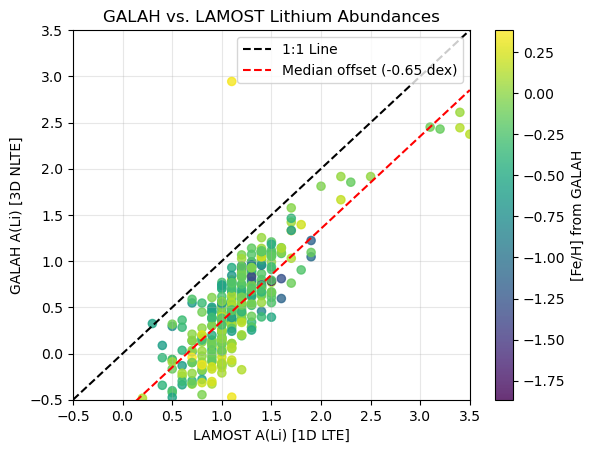

In [69]:
#true plot
sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['a_li_lamost'],
    K2_GALAH_x_k2_LAMOST['a_li_galah'],
    #c=K2_x_GALAH_LAMOST['teff'], # Temperature from GALAH
    c=K2_GALAH_x_k2_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-0.5, 3.5]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('LAMOST A(Li) [1D LTE]')
plt.ylabel('GALAH A(Li) [3D NLTE]')
plt.title('GALAH vs. LAMOST Lithium Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()

In [70]:
### Computing the offset for the master catalog of K2, Kepler, TESS X GALAH and LAMOST
import pandas as pd

# Load master catalog
df = pd.read_csv('../../data/extra_catalogs/K2_Kepler_TESS_x_GALAH_LAMOST.csv')

# Select stars observed by both surveys
both = df[df['survey_match'] == 'both'].copy()

# Filter for clean detections in both
# GALAH: flag_a_li == 0, flag_sp == 0, snr_px_ccd3 > 30
# LAMOST: Lim == 0 (detection), Flag_lamost >= 1, S_N_lamost > 20
clean = both[
    (both['flag_a_li'] == 0)
    & (both['flag_sp'] == 0)
    & (both['snr_px_ccd3'] > 30)
    & (both['Lim'] == 0)
    & (both['S_N_lamost'] > 20)
].copy()

# Direct offset calculation on the same row:
clean['delta_a_li'] = clean['a_li'] - clean['A_Li_']

print(f'Clean comparison stars: {len(clean)}')
print(f"Median offset (GALAH - LAMOST): {clean['delta_a_li'].median():.3f} dex") 

Clean comparison stars: 334
Median offset (GALAH - LAMOST): -0.648 dex


/tmp/ipykernel_13192/3017508361.py:5: DtypeWarning: Columns (2,3,65,68,70,79,81,83,97,98,100) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../../data/extra_catalogs/K2_Kepler_TESS_x_GALAH_LAMOST.csv')


The sign of the corrections agree with Wang et al. But they are very large 0.65. This can be due to metodology which in Wang et al 2024 shift the stars 0.3 dex or 3D-NLTE corrections which according to Wang et al 2020 can be up to 0.5 dex (see picture below). In order to explore this possibility we will use bredalink to apply the 3D NLTE correction over the 1D LTE aundances of Ding et al. 


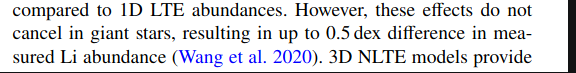

### 3D NLTE of GALAH vs 3D NLTE from LAMOST

In [71]:
K2_x_GALAH_LAMOST_columns = K2_GALAH_x_k2_LAMOST.columns
a=K2_x_GALAH_LAMOST_columns[-15:]
print(a)

Index(['S_N', 'RVel', 'Teff_2', 'logg_2', '__Fe_H_', 'A_Li_', 'DelA_Li_',
       'e_DelA_Li_', 'Flag', 'Lim', 'DR7', 'Simbad', 'a_li_galah',
       'a_li_lamost', 'delta_a_li'],
      dtype='object')


In [72]:
#Transform LAMOST A(Li) to 3D NLTE using Breidablik

# initialise model
model = Nlte()
# find 3D NLTE correction
def Get_3D_NLTE_Li_abundance(teff, logg, fe_h, a_li_1DLTE):
    values = np.broadcast_arrays(
        np.asarray(teff, dtype=float),
        np.asarray(logg, dtype=float),
        np.asarray(fe_h, dtype=float),
        np.asarray(a_li_1DLTE, dtype=float),
    )
    shape = values[0].shape
    flat_values = [v.ravel() for v in values]

    corrected = np.full(flat_values[0].size, np.nan)
    for i, (t, g, f, a) in enumerate(zip(*flat_values)):
        if np.isfinite([t, g, f, a]).all():
            nltec = model.nlte_correction(t, g, f, a)
            corrected[i] = a + float(np.asarray(nltec).squeeze())

    result = corrected.reshape(shape)
    if isinstance(a_li_1DLTE, pd.Series):
        return pd.Series(result, index=a_li_1DLTE.index)
    return result.item() if result.ndim == 0 else result


K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte'] = Get_3D_NLTE_Li_abundance(
    K2_GALAH_x_k2_LAMOST['Teff_2'],
    K2_GALAH_x_k2_LAMOST['logg_2'],
    K2_GALAH_x_k2_LAMOST['__Fe_H_'],
    K2_GALAH_x_k2_LAMOST['a_li_lamost'],
)

K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'] = (
    K2_GALAH_x_k2_LAMOST['a_li_galah']
    - K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte']
)

# Compares 3D-NLTE Li abundances from GALAH and 3D NLTE LAMOST for the same stars

med_offset = K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): -0.608 dex
Standard Deviation: 0.307 dex
Median Absolute Deviation: 0.208 dex


/home/juan-idarraga/packages/miniconda3/envs/thesis/lib/python3.10/site-packages/breidablik/interpolate/nlte.py:72: UserWarning: Input abundance is outside of the grid, results are extrapolated and may not be reliable.
  warnings.warn('Input abundance is outside of the grid, results are extrapolated and may not be reliable.')


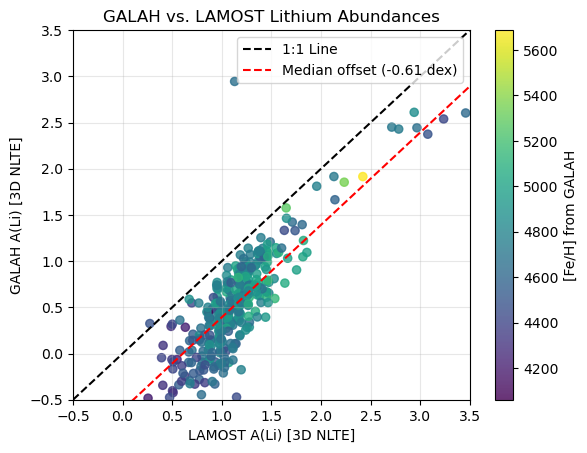

In [73]:
sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte'],
    K2_GALAH_x_k2_LAMOST['a_li_galah'],
    c=K2_GALAH_x_k2_LAMOST['teff'], # Temperature from GALAH
    #c=K2_x_GALAH_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-0.5, 3.5]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('LAMOST A(Li) [3D NLTE]')
plt.ylabel('GALAH A(Li) [3D NLTE]')
plt.title('GALAH vs. LAMOST Lithium Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()

The median offset between GALAH and LAMOSt is still very high. Probing that in this case the 3DNLTE correction to the 1D LTE abundances from Ding et al. only contributed in a 0.04 dex and that most of the offset is due to the difference in methodology. 

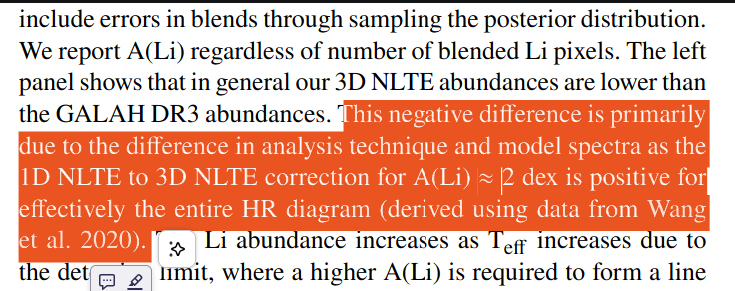

As we can see above even for Wang et al. the methodology offset is very large 0.3

### Offset in Temperature

In [74]:
# using the same catalog --> K2_x_GALAH_LAMOST

K2_GALAH_x_k2_LAMOST['delta_teff'] = (
    K2_GALAH_x_k2_LAMOST['teff'] # GALAH Teff
    - K2_GALAH_x_k2_LAMOST['Teff_2'] # LAMOST Teff
)


med_offset = K2_GALAH_x_k2_LAMOST['delta_teff'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_teff'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_teff'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f}')
print(f'Standard Deviation: {std_offset:.3f}')
print(f'Median Absolute Deviation: {mad_offset:.3f}')

Median Offset (GALAH - LAMOST): 4.349
Standard Deviation: 67.539
Median Absolute Deviation: 35.897


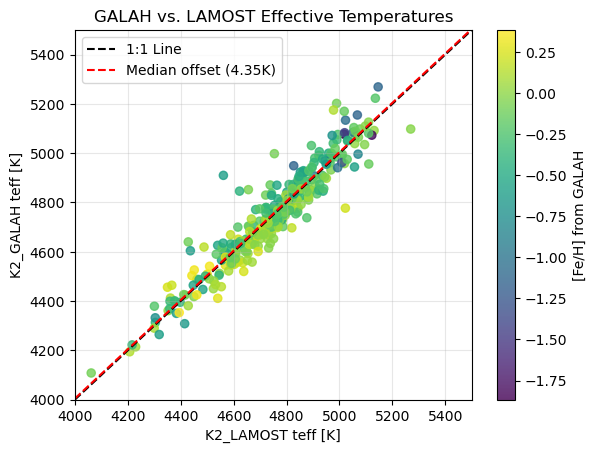

In [75]:


sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['teff'],
    K2_GALAH_x_k2_LAMOST['Teff_2'],
    #c=K2_x_GALAH_LAMOST['teff'], # Temperature from GALAH
    c=K2_GALAH_x_k2_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [4000, 5500]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f}K)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('K2_LAMOST teff [K]')
plt.ylabel('K2_GALAH teff [K]')
plt.title('GALAH vs. LAMOST Effective Temperatures')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()


¿How was the temperature derived for GALAH and Lamost?



### Offset in logg

In [76]:

K2_GALAH_x_k2_LAMOST['delta_logg'] = (
    K2_GALAH_x_k2_LAMOST['logg'] # GALAH logg
    - K2_GALAH_x_k2_LAMOST['logg_2'] # LAMOST logg
)


med_offset = K2_GALAH_x_k2_LAMOST['delta_logg'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_logg'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_logg'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): 0.018 dex
Standard Deviation: 0.148 dex
Median Absolute Deviation: 0.082 dex


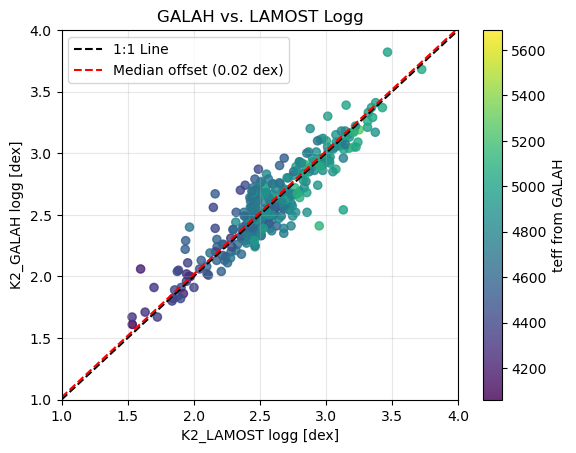

In [77]:

sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['logg'],
    K2_GALAH_x_k2_LAMOST['logg_2'],
    c=K2_GALAH_x_k2_LAMOST['teff'], # Temperature from GALAH
    #c=K2_x_GALAH_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [1, 4]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('K2_LAMOST logg [dex]')
plt.ylabel('K2_GALAH logg [dex]')
plt.title('GALAH vs. LAMOST Logg')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='teff from GALAH')

plt.show()


### Offset in iron/h

In [78]:
K2_GALAH_x_k2_LAMOST['delta_fe_h'] = (
    K2_GALAH_x_k2_LAMOST['fe_h_2'] # GALAH logg
    - K2_GALAH_x_k2_LAMOST['__Fe_H_'] # LAMOST logg
)


med_offset = K2_GALAH_x_k2_LAMOST['delta_fe_h'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_fe_h'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_fe_h'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): 0.006 dex
Standard Deviation: 0.056 dex
Median Absolute Deviation: 0.033 dex


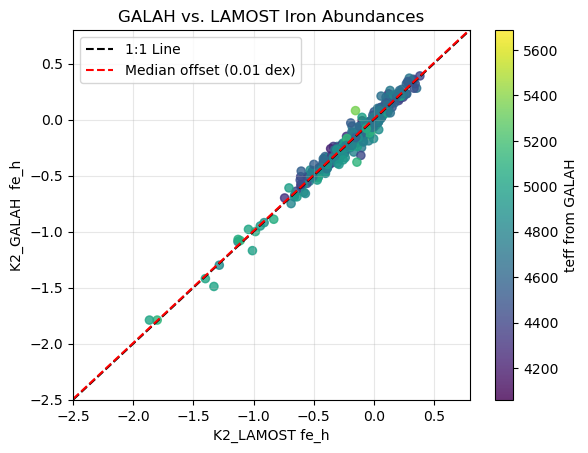

In [79]:

sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['fe_h_2'],
    K2_GALAH_x_k2_LAMOST['__Fe_H_'],
    c=K2_GALAH_x_k2_LAMOST['teff'], # Temperature from GALAH
    #c=K2_x_GALAH_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-2.5, 0.8]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('K2_LAMOST fe_h')
plt.ylabel('K2_GALAH  fe_h')
plt.title('GALAH vs. LAMOST Iron Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='teff from GALAH')

plt.show()
